# Fixed-pair SGM seed-set classification: FAQ and GOAT

This notebook asks whether Graph-A seed-set features distinguish successful from unsuccessful **single SGM runs**. It analyzes all six fixed-pair collections side by side: three graph models (ER, PAPER, Chung–Lu, each at mean degree about 16) and two solvers, standard **FAQ-SGM** and optimal-transport **GOAT-SGM**.

**Outcome.** `sgm_success = 1` when the run's final unseeded accuracy is at least 0.90. Each seed set has one run. GOAT runs are deterministic. A FAQ label is one draw: in calibration, repeat FAQ runs gave the same label 63–93% of the time.

**Seed budgets differ by solver.** Budgets are 29/12 for ER, 31/12 for PAPER and 27/9 for Chung–Lu (FAQ/GOAT). Compare predictability within a solver; compare feature patterns, not accuracy levels, across solvers.

**Evaluation design (same as the percolation notebook).**
- Model diagnostics use 5-fold stratified cross-validation on the 400 uniformly random training sets.
- Final models are fitted on the training groups selected by `TRAIN_ON`.
- They are evaluated once on the 200 held-out uniformly random test sets.
- The test sets are not used for model or feature selection.

**Sections**
1. Load and verify the collections
2. Label and accuracy distribution
3. Predictors and their correlation with success
4. Constructed seed sets: degree bias and degree-matched contrasts
5. Cross-validation on random training sets
6. Held-out test evaluation
7. Feature importance
8. Reference diagnostic: edge noise around the seeds (uses graph B and the true matching)
9. Summary and interpretation limits

In [1]:
import json
import os
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

EXPERIMENT_DIR = Path.cwd().resolve()
if EXPERIMENT_DIR.name != 'fixed_pair_seed_set_classification':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'fixed_pair_seed_set_classification'
DATA_ROOT = EXPERIMENT_DIR / 'data' / 'sgm_fixed_pairs_2026-10-13'

GRAPH_MODELS = ['sparse_er', 'paper_pa', 'chung_lu']
SOLVERS = ['faq', 'goat']
PAIR_SEEDS = {'sparse_er': 88424077, 'paper_pa': 7301002, 'chung_lu': 18472911}
PAIR_INDEX = 1

TRAIN_ON = 'all'  # 'all': random + constructed training sets; 'random': the 400 random sets only
INCLUDE_SIGNATURE_ROBUSTNESS = True  # add signature uniqueness at radius 2 and 4 (see Section 3)
SUCCESS_THRESHOLD = 0.90
CV_FOLDS = 5
N_BOOTSTRAP = 1000  # resamples for held-out ROC-AUC intervals
PERMUTATION_REPEATS = 30
RUN_NOISE_DIAGNOSTIC = True  # Section 8; needs the saved graph pairs
RANDOM_STATE = 42
DEGREE = 'seed_nonseed_degree_mean'

MODEL_LABELS = {'sparse_er': 'ER', 'paper_pa': 'PAPER', 'chung_lu': 'Chung–Lu'}
SOLVER_LABELS = {'faq': 'FAQ', 'goat': 'GOAT'}
GROUP_LABELS = {
    ('train', 'random'): 'Random (train)',
    ('test', 'random'): 'Random (test)',
    ('train', 'degree_weighted'): 'Degree-weighted',
    ('train', 'degree_controlled'): 'Degree-matched contrasts',
    ('train', 'swap_path'): 'Swap paths',
}
FEATURE_LABELS = {
    'seed_nonseed_degree_mean': 'Seed–nonseed degree',
    'seed_harmonic_mean': 'Seed harmonic mean',
    'nonseed_covered_fraction': 'Nonseed coverage',
    'nonseed_witness_overlap_fraction': 'Witness overlap',
    'nonseed_witness_pair_mass_mean': 'Witness-pair mass',
    'nonseed_nearest_seed_distance_mean': 'Nearest-seed distance',
    'nonseed_three_hop_seed_count_mean': 'Seeds within 3 hops',
    'nonseed_distance_signature_unique_fraction_r3': 'Signature uniqueness r=3',
    'seed_nonseed_neighborhood_jaccard_mean': 'Seed-neighborhood Jaccard',
    'nonseed_distance_signature_unique_fraction_r2': 'Signature uniqueness r=2',
    'nonseed_distance_signature_unique_fraction_r4': 'Signature uniqueness r=4',
}

if TRAIN_ON not in ('all', 'random'):
    raise ValueError("TRAIN_ON must be 'all' or 'random'.")
if not DATA_ROOT.exists():
    raise FileNotFoundError(f'Collection folder not found: {DATA_ROOT}. Open the notebook inside the project.')

DATASETS = [(model, solver) for solver in SOLVERS for model in GRAPH_MODELS]
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
print('Collection root:', DATA_ROOT)
print('Datasets:', ', '.join(f'{MODEL_LABELS[m]} · {SOLVER_LABELS[s]}' for m, s in DATASETS))

Collection root: /Users/langsong/Desktop/Seeded-Graph-Matching/fixed_pair_seed_set_classification/data/sgm_fixed_pairs_2026-10-13
Datasets: ER · FAQ, PAPER · FAQ, Chung–Lu · FAQ, ER · GOAT, PAPER · GOAT, Chung–Lu · GOAT


Helper functions for labels, heatmaps and bootstrap intervals.

In [2]:
def dataset_label(key):
    model, solver = key
    return f'{MODEL_LABELS[model]} · {SOLVER_LABELS[solver]}'


def feature_label(feature):
    return FEATURE_LABELS.get(feature, feature)


def heatmap(ax, table, vmin, vmax, cmap='RdBu_r', fmt='{:.2f}', fontsize=8, annotate=True):
    """Draw a labeled heatmap of a DataFrame; NaN cells are left blank."""
    values = table.to_numpy(dtype=float)
    image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
    ax.set_xticks(range(table.shape[1]))
    ax.set_xticklabels(table.columns, rotation=35, ha='right', fontsize=fontsize)
    ax.set_yticks(range(table.shape[0]))
    ax.set_yticklabels(table.index, fontsize=fontsize)
    if annotate:
        middle, half_range = (vmin + vmax) / 2, (vmax - vmin) / 2
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                if np.isfinite(values[i, j]):
                    dark = abs(values[i, j] - middle) > 0.6 * half_range
                    ax.text(j, i, fmt.format(values[i, j]), ha='center', va='center',
                            fontsize=fontsize - 1, color='white' if dark else 'black')
    return image


def bootstrap_auc(y_true, scores, reference=None, n_boot=N_BOOTSTRAP, seed=RANDOM_STATE):
    """Percentile bootstrap intervals for ROC-AUC, plus paired differences from a reference model."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    draws = {name: [] for name in scores}
    differences = {name: [] for name in scores if reference is not None and name != reference}
    for _ in range(n_boot):
        index = rng.integers(0, len(y_true), len(y_true))
        sample = y_true[index]
        if sample.min() == sample.max():
            continue
        aucs = {name: roc_auc_score(sample, np.asarray(values)[index]) for name, values in scores.items()}
        for name, value in aucs.items():
            draws[name].append(value)
        for name in differences:
            differences[name].append(aucs[name] - aucs[reference])
    intervals = {name: tuple(np.percentile(values, [2.5, 97.5])) for name, values in draws.items()}
    paired = {name: (float(np.mean(values)), *np.percentile(values, [2.5, 97.5]))
              for name, values in differences.items()}
    return intervals, paired

## 1. Load and verify the collections

Each collection must be complete and have one run per seed set. Seed sets must be unique, labels must match the 0.90 threshold, and the test split must contain only uniformly random sets. Features that are constant on the random training sets are dropped for that dataset.

In [3]:
def read_success(series):
    """Read a saved boolean label robustly (bool, 0/1 or 'True'/'False')."""
    mapped = series.astype(str).str.strip().str.lower().map(
        {'true': 1, 'false': 0, '1': 1, '0': 0, '1.0': 1, '0.0': 0})
    if mapped.isna().any():
        raise ValueError('Unreadable sgm_success values.')
    return mapped.astype(int)


collections = {}
summary_rows = []
for key in DATASETS:
    model, solver = key
    folder = DATA_ROOT / solver / model / f'pair_{PAIR_INDEX}_seed_{PAIR_SEEDS[model]}'
    csv_path = folder / f'{model}_seed_sets.csv'
    metadata_path = folder / f'{model}_seed_sets.metadata.json'
    if not csv_path.exists() or not metadata_path.exists():
        raise FileNotFoundError(f'Collection not found: {folder}')
    data = pd.read_csv(csv_path)
    metadata = json.loads(metadata_path.read_text(encoding='utf-8'))

    problems = []
    if metadata.get('status') != 'complete':
        problems.append(f"status is {metadata.get('status')!r}")
    if len(data) != metadata.get('rows') or metadata.get('rows_completed') != len(data):
        problems.append('row count differs from the completion metadata')
    if metadata.get('solver') != solver or not data['solver'].eq(solver).all():
        problems.append('solver differs from the folder name')
    if metadata.get('solver_runs') != 1:
        problems.append('expected one SGM run per seed set')
    if data['seed_vertices_graph1'].duplicated().any():
        problems.append('duplicate seed sets')
    data['success'] = read_success(data['sgm_success'])
    threshold_label = data['final_unseeded_accuracy'].ge(SUCCESS_THRESHOLD).astype(int)
    if not threshold_label.equals(data['success']):
        problems.append('saved labels differ from the configured threshold')
    if not data.loc[data['data_split'].eq('test'), 'sampling_strategy'].eq('random').all():
        problems.append('the test split contains constructed sets')
    if problems:
        raise ValueError(f'{folder}: ' + '; '.join(problems))

    train = data[data['data_split'].eq('train')].copy()
    random_train = train[train['sampling_strategy'].eq('random')].copy()
    test = data[data['data_split'].eq('test')].copy()
    for name, part in [('random training', random_train), ('test', test)]:
        if part['success'].nunique() < 2:
            raise ValueError(f'{dataset_label(key)}: the {name} sets contain one class only.')

    candidates = list(metadata['feature_columns'])
    if INCLUDE_SIGNATURE_ROBUSTNESS:
        candidates += list(metadata.get('robustness_feature_columns', []))
    missing = [f for f in candidates if f not in data.columns]
    if missing:
        raise ValueError(f'{dataset_label(key)}: missing feature columns {missing}')
    constant = [f for f in candidates if random_train[f].nunique(dropna=True) < 2]
    features = [f for f in candidates if f not in constant]
    if DEGREE not in features:
        raise ValueError(f'{dataset_label(key)}: the degree feature is missing or constant.')

    collections[key] = dict(data=data, metadata=metadata, folder=folder, train=train,
                            random_train=random_train, test=test, features=features,
                            fit_train=train if TRAIN_ON == 'all' else random_train)
    summary_rows.append({
        'Dataset': dataset_label(key),
        'Graph-pair seed': metadata['graph_pair_seed'],
        'Seed budget k': metadata['config']['n_seeds'],
        'rho': metadata['config']['rho'],
        'GOAT regularizer': metadata['solver_options']['transport_regularizer'] if solver == 'goat' else None,
        'Sets': len(data),
        'Random train': len(random_train),
        'Constructed train': len(train) - len(random_train),
        'Random test': len(test),
        'Predictors': len(features),
        'Dropped (constant)': ', '.join(feature_label(f) for f in constant) or '—',
        'Warning runs': metadata.get('warning_runs', 0),
        'Runs at iteration limit': metadata.get('nonconverged_runs', 0),
        'Collection minutes': metadata.get('collection_minutes'),
    })

collection_summary = pd.DataFrame(summary_rows).set_index('Dataset')
display(collection_summary)

,Graph-pair seed,Seed budget k,rho,GOAT regularizer,Sets,Random train,Constructed train,Random test,Predictors,Dropped (constant),Warning runs,Runs at iteration limit,Collection minutes
Dataset,,,,,,,,,,,,,
ER · FAQ,88424077,29,0.50,NaN,1000,400,400,200,11,—,0,0,15.01
PAPER · FAQ,7301002,31,0.40,NaN,1000,400,400,200,11,—,0,2,19.73
Chung–Lu · FAQ,18472911,27,0.45,NaN,1000,400,400,200,11,—,0,3,18.90
ER · GOAT,88424077,12,0.50,100.0,1000,400,400,200,11,—,0,1,28.12
PAPER · GOAT,7301002,12,0.40,300.0,1000,400,400,200,11,—,0,7,47.08
Chung–Lu · GOAT,18472911,9,0.45,300.0,1000,400,400,200,11,—,0,10,32.48


## 2. Label and accuracy distribution

Success fractions are shown by sampling group. The **uniformly random** sets are the reference population; the degree-weighted and degree-matched groups were constructed to widen the feature range, so their success rates need not match. The histograms use the 600 random sets per dataset. A clean label has few runs between 0.5 and 0.9 accuracy.

Success fraction by sampling group


Group,Random (train),Random (test),Degree-weighted,Degree-matched contrasts
Dataset,,,,
ER · FAQ,0.738,0.735,0.850,0.755
PAPER · FAQ,0.540,0.510,0.725,0.590
Chung–Lu · FAQ,0.678,0.720,0.775,0.700
ER · GOAT,0.665,0.675,0.725,0.660
PAPER · GOAT,0.275,0.260,0.375,0.315
Chung–Lu · GOAT,0.638,0.740,0.640,0.595


Label separation on the uniformly random sets


,Random sets,Success fraction,Lowest success accuracy,Highest failure accuracy,Runs with accuracy 0.5–0.9
Dataset,,,,,
ER · FAQ,600,0.737,1.000,0.294,0
PAPER · FAQ,600,0.530,1.000,0.652,1
Chung–Lu · FAQ,600,0.692,0.976,0.353,0
ER · GOAT,600,0.668,1.000,0.281,0
PAPER · GOAT,600,0.270,1.000,0.452,0
Chung–Lu · GOAT,600,0.672,0.975,0.381,0


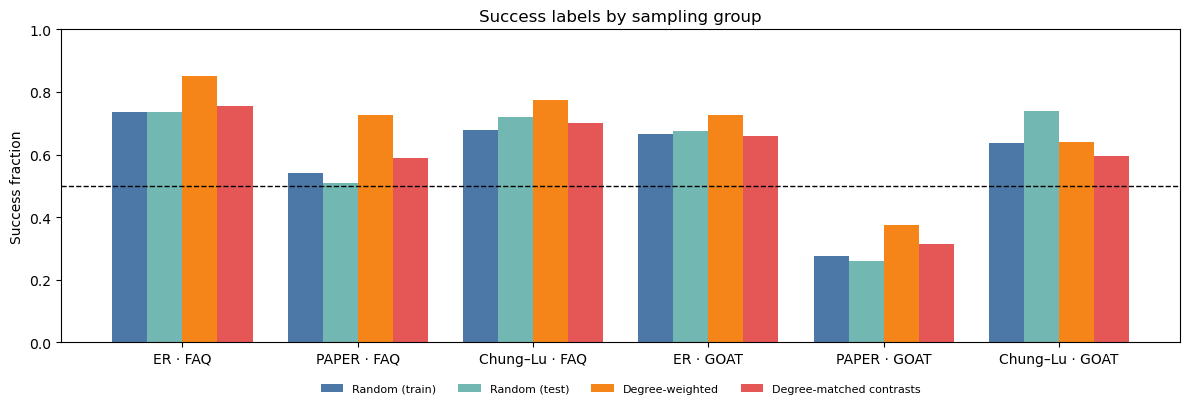

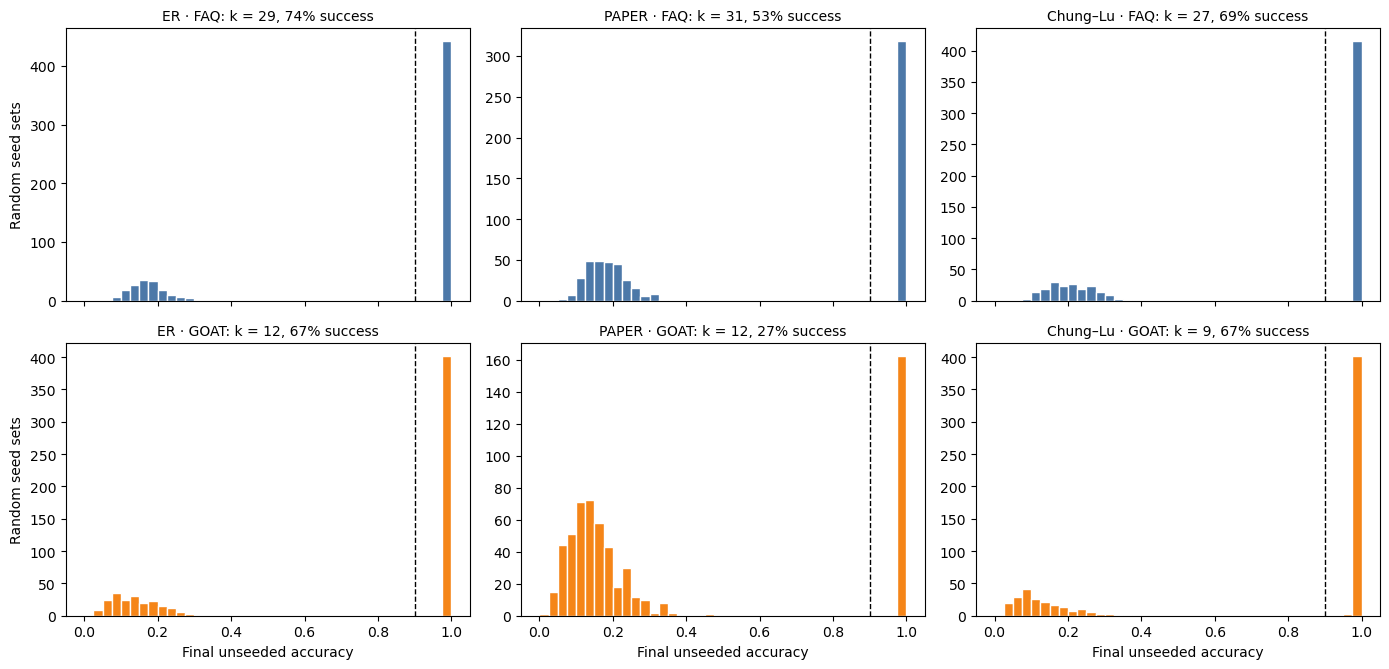

In [4]:
group_rows = []
for key, c in collections.items():
    for (split, strategy), group in c['data'].groupby(['data_split', 'sampling_strategy'], sort=False):
        group_rows.append({
            'Dataset': dataset_label(key),
            'Group': GROUP_LABELS.get((split, strategy), f'{split} · {strategy}'),
            'Sets': len(group),
            'Successes': int(group['success'].sum()),
            'Success fraction': group['success'].mean(),
            'Mean accuracy': group['final_unseeded_accuracy'].mean(),
        })
group_summary = pd.DataFrame(group_rows)
group_order = [g for g in GROUP_LABELS.values() if g in set(group_summary['Group'])]
dataset_order = [dataset_label(k) for k in DATASETS]
success_by_group = (group_summary.pivot(index='Dataset', columns='Group', values='Success fraction')
                    .reindex(index=dataset_order, columns=group_order))
print('Success fraction by sampling group')
display(success_by_group.round(3))

label_quality = []
for key, c in collections.items():
    random_sets = c['data'][c['data']['sampling_strategy'].eq('random')]
    accuracy = random_sets['final_unseeded_accuracy']
    label_quality.append({
        'Dataset': dataset_label(key),
        'Random sets': len(random_sets),
        'Success fraction': random_sets['success'].mean(),
        'Lowest success accuracy': accuracy[accuracy >= SUCCESS_THRESHOLD].min(),
        'Highest failure accuracy': accuracy[accuracy < SUCCESS_THRESHOLD].max(),
        'Runs with accuracy 0.5–0.9': int(accuracy.between(0.5, SUCCESS_THRESHOLD, inclusive='left').sum()),
    })
print('Label separation on the uniformly random sets')
display(pd.DataFrame(label_quality).set_index('Dataset').round(3))

fig, ax = plt.subplots(figsize=(12, 4.2))
width = 0.8 / len(group_order)
colors = ['#4C78A8', '#72B7B2', '#F58518', '#E45756', '#54A24B']
for index, group in enumerate(group_order):
    ax.bar(np.arange(len(dataset_order)) + (index - (len(group_order) - 1) / 2) * width,
           success_by_group[group], width=width, label=group, color=colors[index % len(colors)])
ax.axhline(0.5, color='black', linestyle='--', linewidth=1)
ax.set_xticks(range(len(dataset_order)))
ax.set_xticklabels(dataset_order)
ax.set_ylim(0, 1)
ax.set_ylabel('Success fraction')
ax.set_title('Success labels by sampling group')
ax.legend(ncol=len(group_order), fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(SOLVERS), len(GRAPH_MODELS), figsize=(14, 3.4 * len(SOLVERS)),
                         sharex=True, squeeze=False)
for row, solver in enumerate(SOLVERS):
    for col, model in enumerate(GRAPH_MODELS):
        ax = axes[row, col]
        c = collections[(model, solver)]
        random_sets = c['data'][c['data']['sampling_strategy'].eq('random')]
        ax.hist(random_sets['final_unseeded_accuracy'], bins=np.linspace(0, 1, 41),
                color='#F58518' if solver == 'goat' else '#4C78A8', edgecolor='white')
        ax.axvline(SUCCESS_THRESHOLD, color='black', linestyle='--', linewidth=1)
        ax.set_title(f"{dataset_label((model, solver))}: k = {c['metadata']['config']['n_seeds']}, "
                     f"{random_sets['success'].mean():.0%} success", fontsize=10)
        if row == len(SOLVERS) - 1:
            ax.set_xlabel('Final unseeded accuracy')
        if col == 0:
            ax.set_ylabel('Random seed sets')
plt.tight_layout()
plt.show()

## 3. Predictors and their correlation with success

The predictors are Graph-A seed-set features computed before SGM ran. `h0_accuracy`, the objective, iteration counts and accuracies are solver outcomes and are **not** predictors.

**Signature radius.** At the FAQ budgets (27–31 seeds) almost every nonseed already has a unique radius-3 distance signature, so that feature barely varies. The radius-2 version (which seeds are adjacent) still varies, which is why `INCLUDE_SIGNATURE_ROBUSTNESS = True` by default. The first table flags predictors where most sets share a single value; they stay in the models but carry almost no information there.

All correlations in this section use the **random training sets only**, so the test sets stay untouched.

Share of random training sets at the most common value (0.80 or more is flagged as near-constant)


,ER · FAQ,PAPER · FAQ,Chung–Lu · FAQ,ER · GOAT,PAPER · GOAT,Chung–Lu · GOAT
Seed–nonseed degree,0.035,0.025,0.018,0.050,0.048,0.030
Seed harmonic mean,0.008,0.008,0.005,0.008,0.008,0.008
Nonseed coverage,0.045,0.055,0.032,0.062,0.045,0.035
Witness overlap,0.012,0.008,0.005,0.015,0.018,0.015
Witness-pair mass,0.032,0.028,0.018,0.082,0.068,0.068
Nearest-seed distance,0.040,0.052,0.028,0.042,0.040,0.032
Seeds within 3 hops,0.030,0.032,0.020,0.038,0.038,0.028
Signature uniqueness r=3,0.982,0.990,0.572,0.032,0.028,0.028
Seed-neighborhood Jaccard,0.002,0.002,0.002,0.002,0.002,0.002
Signature uniqueness r=2,0.060,0.058,0.062,0.135,0.138,0.150


ER · FAQ: near-constant -> Signature uniqueness r=3, Signature uniqueness r=4
PAPER · FAQ: near-constant -> Signature uniqueness r=3, Signature uniqueness r=4
Chung–Lu · FAQ: near-constant -> Signature uniqueness r=4
Spearman correlation between each feature and success (random training sets)


,ER · FAQ,PAPER · FAQ,Chung–Lu · FAQ,ER · GOAT,PAPER · GOAT,Chung–Lu · GOAT
Seed–nonseed degree,0.130,0.202,0.177,0.126,0.187,-0.069
Seed harmonic mean,0.114,0.180,0.247,0.144,0.157,-0.090
Nonseed coverage,0.062,0.122,0.135,0.095,0.166,-0.060
Witness overlap,0.138,0.171,0.199,0.109,0.132,-0.068
Witness-pair mass,0.130,0.170,0.203,0.114,0.162,-0.088
Nearest-seed distance,-0.064,-0.122,-0.132,-0.068,-0.164,0.078
Seeds within 3 hops,0.075,0.172,0.203,0.139,0.048,-0.004
Signature uniqueness r=3,-0.036,0.058,0.008,0.128,0.136,0.097
Seed-neighborhood Jaccard,0.098,0.120,0.202,0.115,0.090,-0.064
Signature uniqueness r=2,0.096,0.249,0.193,0.069,0.082,-0.104


Single-feature ROC-AUC (random training sets; above 0.5 means higher values go with success)


,ER · FAQ,PAPER · FAQ,Chung–Lu · FAQ,ER · GOAT,PAPER · GOAT,Chung–Lu · GOAT
Seed–nonseed degree,0.585,0.617,0.609,0.577,0.621,0.459
Seed harmonic mean,0.575,0.604,0.652,0.588,0.602,0.446
Nonseed coverage,0.541,0.570,0.584,0.558,0.607,0.464
Witness overlap,0.591,0.599,0.623,0.567,0.585,0.459
Witness-pair mass,0.585,0.599,0.625,0.570,0.605,0.447
Nearest-seed distance,0.458,0.429,0.418,0.458,0.394,0.547
Seeds within 3 hops,0.550,0.599,0.625,0.585,0.531,0.497
Signature uniqueness r=3,0.495,0.506,0.504,0.578,0.588,0.558
Seed-neighborhood Jaccard,0.564,0.569,0.625,0.570,0.558,0.462
Signature uniqueness r=2,0.563,0.644,0.619,0.542,0.553,0.438


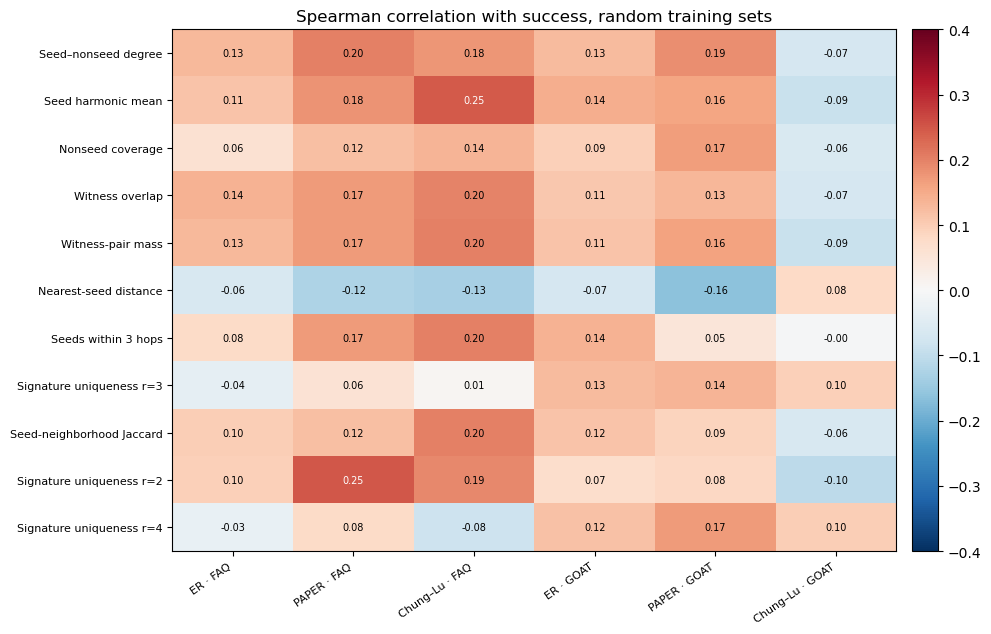

In [5]:
modal_share = pd.DataFrame({
    dataset_label(key): {
        feature_label(f): c['random_train'][f].round(10).value_counts(normalize=True).iloc[0]
        for f in c['features']
    }
    for key, c in collections.items()
})
print('Share of random training sets at the most common value (0.80 or more is flagged as near-constant)')
display(modal_share.round(3))
for column in modal_share.columns:
    flagged = list(modal_share.index[modal_share[column] >= 0.8])
    if flagged:
        print(f'{column}: near-constant -> {", ".join(flagged)}')

spearman = pd.DataFrame({
    dataset_label(key): {
        feature_label(f): c['random_train'][f].corr(c['random_train']['success'], method='spearman')
        for f in c['features']
    }
    for key, c in collections.items()
})
single_auc = pd.DataFrame({
    dataset_label(key): {
        feature_label(f): roc_auc_score(c['random_train']['success'], c['random_train'][f])
        for f in c['features']
    }
    for key, c in collections.items()
})
print('Spearman correlation between each feature and success (random training sets)')
display(spearman.round(3))
print('Single-feature ROC-AUC (random training sets; above 0.5 means higher values go with success)')
display(single_auc.round(3))

fig, ax = plt.subplots(figsize=(10, 0.45 * len(spearman) + 1.5))
image = heatmap(ax, spearman, vmin=-0.4, vmax=0.4)
ax.set_title('Spearman correlation with success, random training sets')
fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02)
plt.tight_layout()
plt.show()

**Correlation among predictors.** Strongly correlated predictors share information, so their individual importances in Section 7 should be read together. The table lists pairs with |Spearman ρ| ≥ 0.8.

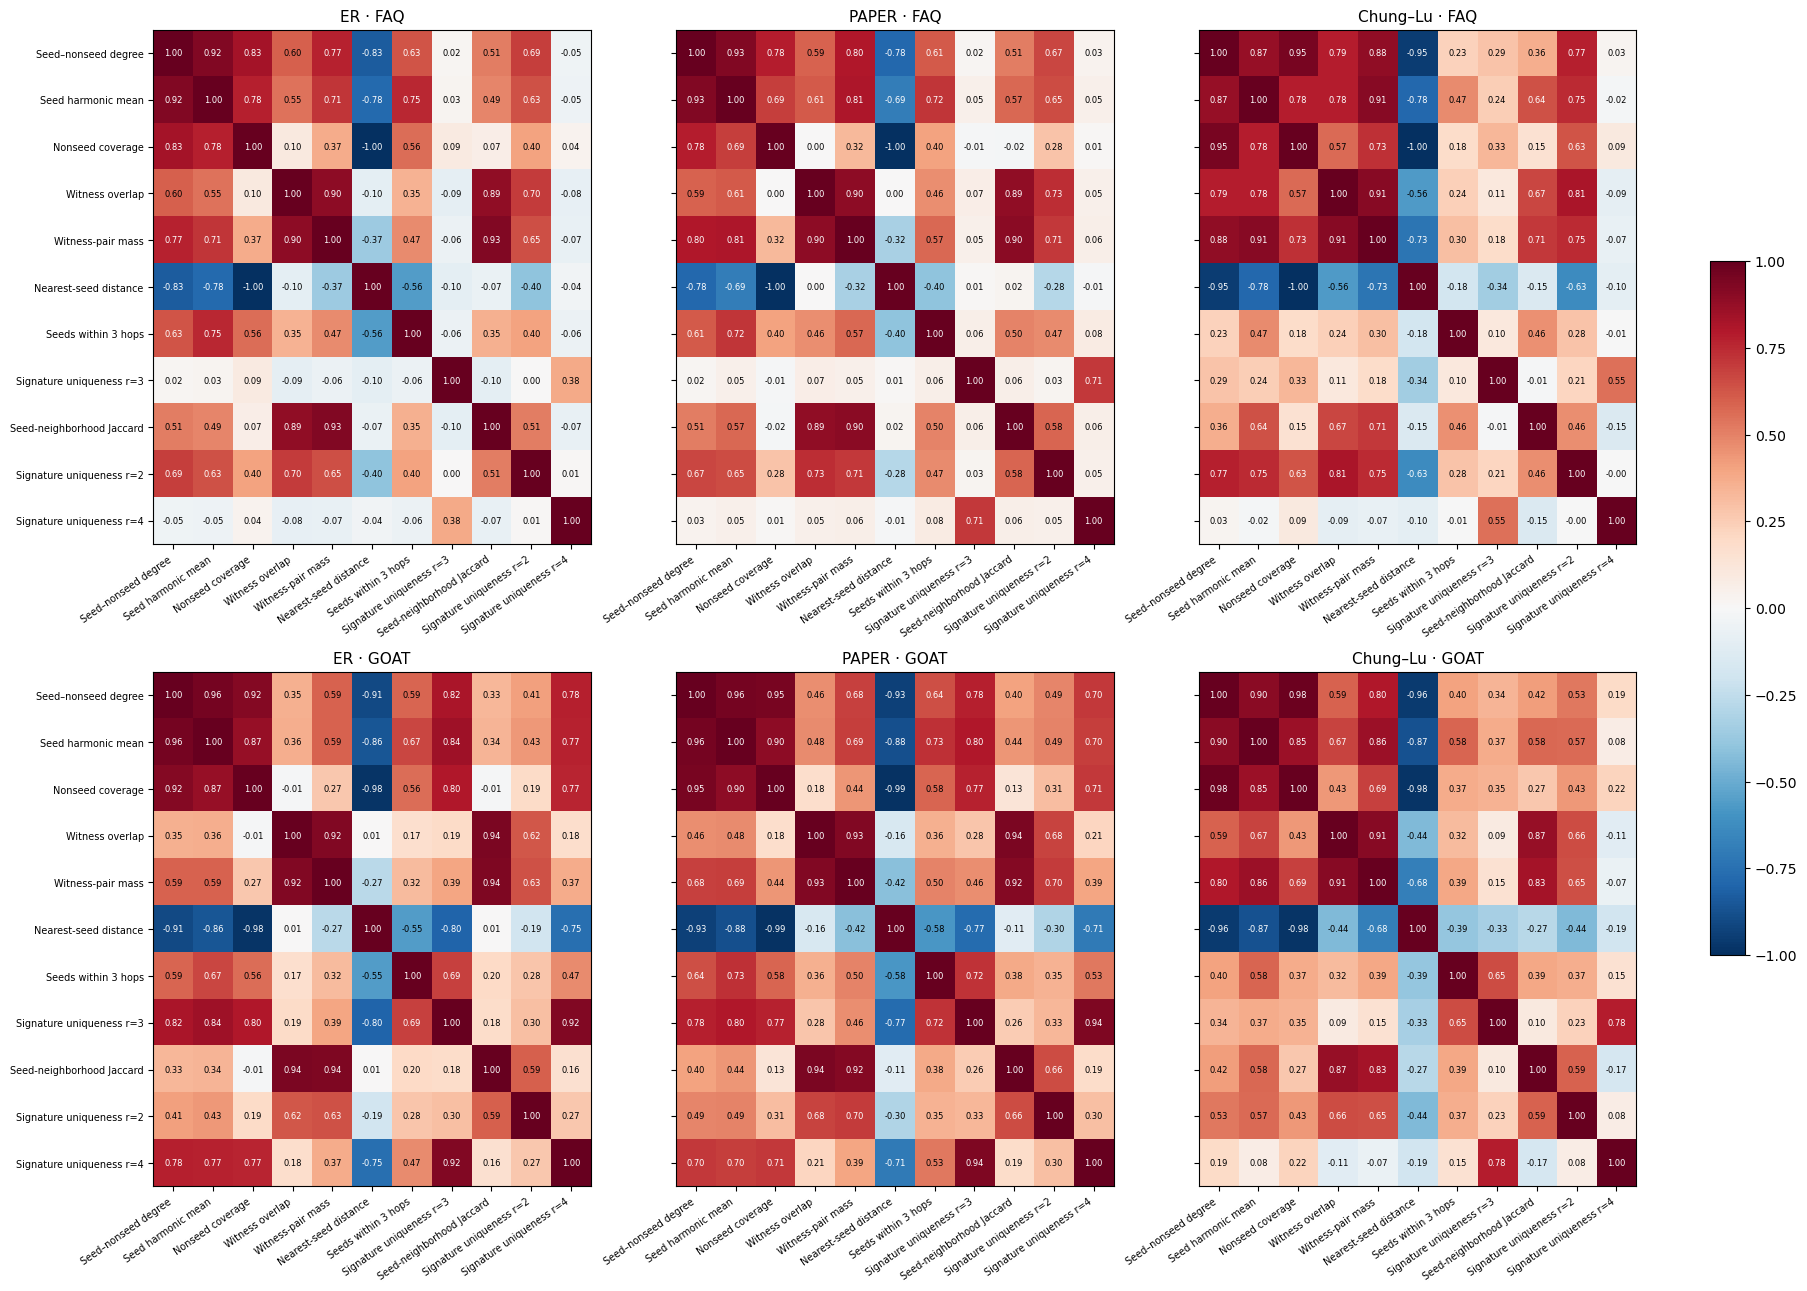

,Dataset,Feature 1,Feature 2,Spearman
0,ER · FAQ,Seed–nonseed degree,Seed harmonic mean,0.924
1,ER · FAQ,Seed–nonseed degree,Nonseed coverage,0.834
2,ER · FAQ,Seed–nonseed degree,Nearest-seed distance,-0.834
3,ER · FAQ,Nonseed coverage,Nearest-seed distance,-1.000
4,ER · FAQ,Witness overlap,Witness-pair mass,0.898
5,ER · FAQ,Witness overlap,Seed-neighborhood Jaccard,0.887
6,ER · FAQ,Witness-pair mass,Seed-neighborhood Jaccard,0.925
7,PAPER · FAQ,Seed–nonseed degree,Seed harmonic mean,0.928
8,PAPER · FAQ,Seed–nonseed degree,Witness-pair mass,0.801
9,PAPER · FAQ,Seed harmonic mean,Witness-pair mass,0.807


In [6]:
fig, axes = plt.subplots(len(SOLVERS), len(GRAPH_MODELS), figsize=(18, 6.4 * len(SOLVERS)),
                         squeeze=False, constrained_layout=True)
strong_pairs = []
first_features = None
for row, solver in enumerate(SOLVERS):
    for col, model in enumerate(GRAPH_MODELS):
        key = (model, solver)
        c = collections[key]
        matrix = c['random_train'][c['features']].corr(method='spearman')
        matrix.index = matrix.columns = [feature_label(f) for f in c['features']]
        image = heatmap(axes[row, col], matrix, vmin=-1, vmax=1, fontsize=7)
        axes[row, col].set_title(dataset_label(key), fontsize=11)
        if col == 0:
            first_features = list(matrix.index)
        elif list(matrix.index) == first_features:
            axes[row, col].set_yticklabels([])
        for i in range(len(matrix)):
            for j in range(i + 1, len(matrix)):
                if abs(matrix.iloc[i, j]) >= 0.8:
                    strong_pairs.append({'Dataset': dataset_label(key), 'Feature 1': matrix.index[i],
                                         'Feature 2': matrix.columns[j], 'Spearman': matrix.iloc[i, j]})
fig.colorbar(image, ax=axes, shrink=0.6)
plt.show()

if strong_pairs:
    display(pd.DataFrame(strong_pairs).round(3))
else:
    print('No predictor pairs with |Spearman| >= 0.8.')

## 4. Constructed seed sets: degree bias and degree-matched contrasts

**Degree-weighted sets** draw seeds with probability proportional to degree^γ: negative γ favors low-degree seeds, positive γ high-degree seeds.

**Degree-matched contrasts** pair two sets with similar seed–nonseed degree, one high and one low on a feature. Among pairs whose outcomes differ, the table counts how often the high-feature set won. The sign-test p-value tests even odds. These are descriptive checks of effects beyond degree; with about 33 pairs per feature they are noisy.

Success fraction of degree-weighted sets by gamma


,ER · FAQ,PAPER · FAQ,Chung–Lu · FAQ,ER · GOAT,PAPER · GOAT,Chung–Lu · GOAT
gamma,,,,,,
-1.0,0.76,0.29,0.41,0.65,0.26,0.59
-0.5,0.65,0.53,0.71,0.62,0.35,0.68
0.5,0.88,0.76,0.82,0.82,0.27,0.61
1.0,0.94,0.88,0.79,0.73,0.21,0.67
2.0,0.88,0.91,0.94,0.73,0.48,0.67
3.0,1.00,1.00,1.00,0.82,0.67,0.64


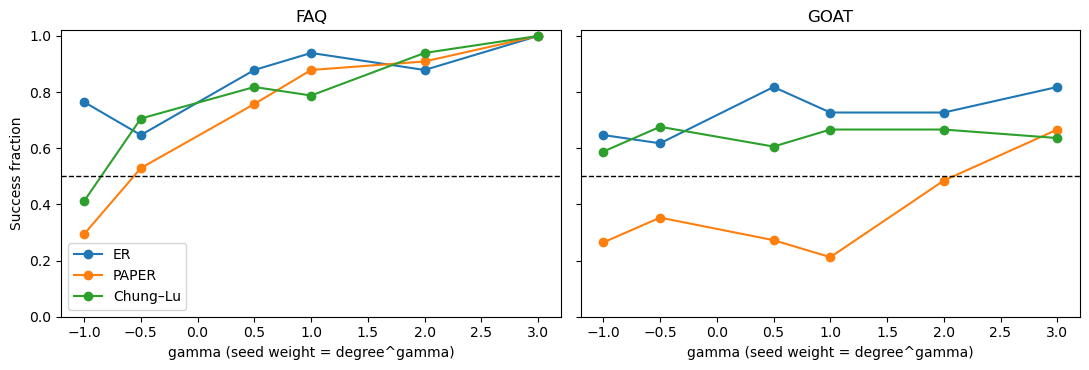

Degree-matched contrasts


,Dataset,Contrast feature,Pairs,Discordant pairs,High wins,Low wins,Sign-test p
0,ER · FAQ,coverage,33,7,2,5,0.453
1,ER · FAQ,pair_mass,34,16,8,8,1.000
2,ER · FAQ,unique_signatures_r3,33,10,5,5,1.000
3,PAPER · FAQ,coverage,33,15,5,10,0.302
4,PAPER · FAQ,pair_mass,34,14,6,8,0.791
5,PAPER · FAQ,unique_signatures_r3,33,17,10,7,0.629
6,Chung–Lu · FAQ,coverage,33,14,5,9,0.424
7,Chung–Lu · FAQ,pair_mass,34,16,9,7,0.804
8,Chung–Lu · FAQ,unique_signatures_r3,33,14,11,3,0.057
9,ER · GOAT,coverage,33,10,6,4,0.754


In [7]:
gamma_table = pd.DataFrame({
    dataset_label(key): c['data'][c['data']['sampling_strategy'].eq('degree_weighted')]
    .groupby('degree_gamma')['success'].mean()
    for key, c in collections.items()
})
gamma_table.index.name = 'gamma'
print('Success fraction of degree-weighted sets by gamma')
display(gamma_table.round(2))

fig, axes = plt.subplots(1, len(SOLVERS), figsize=(11, 3.8), sharey=True, squeeze=False)
for ax, solver in zip(axes[0], SOLVERS):
    for model in GRAPH_MODELS:
        column = dataset_label((model, solver))
        if column in gamma_table:
            ax.plot(gamma_table.index, gamma_table[column], marker='o', label=MODEL_LABELS[model])
    ax.axhline(0.5, color='black', linestyle='--', linewidth=1)
    ax.set_title(SOLVER_LABELS[solver])
    ax.set_xlabel('gamma (seed weight = degree^gamma)')
    ax.set_ylim(0, 1.02)
axes[0, 0].set_ylabel('Success fraction')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

contrast_rows = []
for key, c in collections.items():
    contrasts = c['data'][c['data']['sampling_strategy'].eq('degree_controlled')]
    for feature, group in contrasts.groupby('contrast_feature'):
        paired = group.pivot_table(index='contrast_pair_id', columns='contrast_tail',
                                   values='success', aggfunc='first').dropna()
        high_wins = int(((paired['high'] == 1) & (paired['low'] == 0)).sum())
        low_wins = int(((paired['high'] == 0) & (paired['low'] == 1)).sum())
        discordant = high_wins + low_wins
        contrast_rows.append({
            'Dataset': dataset_label(key), 'Contrast feature': feature, 'Pairs': len(paired),
            'Discordant pairs': discordant, 'High wins': high_wins, 'Low wins': low_wins,
            'Sign-test p': binomtest(high_wins, discordant).pvalue if discordant else np.nan,
        })
contrast_table = pd.DataFrame(contrast_rows)
print('Degree-matched contrasts')
display(contrast_table.round(3))

## 5. Classification models: cross-validation on random training sets

- **No-feature baseline:** predicts the training class frequency.
- **Degree-only logistic regression:** the established degree baseline.
- **Full logistic regression:** a linear model on all standardized predictors.
- **Random forest:** captures nonlinear effects and interactions.

Cross-validation uses only the 400 uniformly random training sets. It is a training diagnostic, separate from the held-out test in Section 6.

In [8]:
def make_model_specs(features):
    logistic = lambda: LogisticRegression(C=1.0, max_iter=5000, random_state=RANDOM_STATE)
    return {
        'No-feature baseline': (features, Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('model', DummyClassifier(strategy='prior')),
        ])),
        'Degree logistic': ([DEGREE], Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', logistic()),
        ])),
        'Full logistic': (features, Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', logistic()),
        ])),
        'Random forest': (features, Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('model', RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features='sqrt',
                                             random_state=RANDOM_STATE, n_jobs=-1)),
        ])),
    }


MODEL_NAMES = list(make_model_specs([DEGREE]))
scoring = {
    'ROC-AUC': 'roc_auc',
    'Average precision': 'average_precision',
    'Balanced accuracy': 'balanced_accuracy',
    'Brier score': 'neg_brier_score',
}
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for key, c in collections.items():
    for name, (columns, estimator) in make_model_specs(c['features']).items():
        scores = cross_validate(estimator, c['random_train'][columns], c['random_train']['success'],
                                cv=cv, scoring=scoring, n_jobs=1, error_score='raise')
        row = {'Dataset': dataset_label(key), 'Model': name}
        for metric in scoring:
            values = scores[f'test_{metric}']
            if metric == 'Brier score':
                values = -values
            row[f'{metric} mean'] = values.mean()
            row[f'{metric} SD'] = values.std(ddof=1)
        cv_rows.append(row)
cv_results = pd.DataFrame(cv_rows)

print(f'{CV_FOLDS}-fold CV ROC-AUC on random training sets (mean)')
display(cv_results.pivot(index='Dataset', columns='Model', values='ROC-AUC mean')
        .reindex(index=dataset_order, columns=MODEL_NAMES).round(3))
print('All CV metrics')
display(cv_results.set_index(['Dataset', 'Model']).round(3))

5-fold CV ROC-AUC on random training sets (mean)


Model,No-feature baseline,Degree logistic,Full logistic,Random forest
Dataset,,,,
ER · FAQ,0.5,0.588,0.534,0.472
PAPER · FAQ,0.5,0.621,0.629,0.614
Chung–Lu · FAQ,0.5,0.610,0.632,0.613
ER · GOAT,0.5,0.577,0.607,0.575
PAPER · GOAT,0.5,0.624,0.612,0.559
Chung–Lu · GOAT,0.5,0.539,0.533,0.516


All CV metrics


ROC-AUC mean  ROC-AUC SD  Average precision mean  Average precision SD  Balanced accuracy mean  Balanced accuracy SD  Brier score mean  Brier score SD
Dataset         Model                                                                                                                                                                      
ER · FAQ        No-feature baseline         0.500       0.000                   0.738                 0.000                   0.500                 0.000             0.194           0.000
                Degree logistic             0.588       0.074                   0.805                 0.039                   0.498                 0.004             0.192           0.007
                Full logistic               0.534       0.090                   0.771                 0.057                   0.495                 0.005             0.198           0.008
                Random forest               0.472       0.059                   0.739                 0.043                   0.486                 0.020             0.211           0.014
PAPER · FAQ     No-feature baseline         0.500       0.000                   0.540                 0.006                   0.500                 0.000             0.248           0.000
                Degree logistic             0.621       0.099                   0.676                 0.100                   0.567                 0.052             0.241           0.016
                Full logistic               0.629       0.060                   0.668                 0.063                   0.582                 0.029             0.238           0.016
                Random forest               0.614       0.069                   0.648                 0.075                   0.590                 0.053             0.242           0.015
Chung–Lu · FAQ  No-feature baseline         0.500       0.000                   0.678                 0.006                   0.500                 0.000             0.219           0.002
                Degree logistic             0.610       0.071                   0.759                 0.043                   0.498                 0.004             0.214           0.006
                Full logistic               0.632       0.039                   0.780                 0.023                   0.535                 0.035             0.211           0.011
                Random forest               0.613       0.048                   0.757                 0.037                   0.531                 0.059             0.218           0.012
ER · GOAT       No-feature baseline         0.500       0.000                   0.665                 0.006                   0.500                 0.000             0.223           0.002
                Degree logistic             0.577       0.036                   0.724                 0.024                   0.502                 0.010             0.220           0.003
                Full logistic               0.607       0.046                   0.755                 0.035                   0.528                 0.024             0.217           0.008
                Random forest               0.575       0.046                   0.720                 0.042                   0.500                 0.025             0.225           0.008
PAPER · GOAT    No-feature baseline         0.500       0.000                   0.275                 0.000                   0.500                 0.000             0.199           0.000
                Degree logistic             0.624       0.078                   0.405                 0.058                   0.511                 0.015             0.192           0.007
                Full logistic               0.612       0.093                   0.416                 0.038                   0.518                 0.027             0.193           0.010
                Random forest               0.559       0.066                   0.358    

## 6. Held-out random-test evaluation

Each model is fitted once on the training rows chosen by `TRAIN_ON` and evaluated on the untouched 200 random test sets. **ROC-AUC is the main measure** (0.5 is chance, 1.0 is perfect ordering). Brackets give 95% bootstrap intervals over test sets; with 200 test sets an AUC is uncertain by roughly ±0.08. The paired difference shows whether the full models beat the degree-only model on the same test sets.

Held-out random-test ROC-AUC, models fitted on TRAIN_ON = 'all'


Model,No-feature baseline,Degree logistic,Full logistic,Random forest
Dataset,,,,
ER · FAQ,"0.500 [0.50, 0.50]","0.691 [0.61, 0.77]","0.607 [0.52, 0.69]","0.579 [0.48, 0.67]"
PAPER · FAQ,"0.500 [0.50, 0.50]","0.679 [0.60, 0.75]","0.661 [0.58, 0.73]","0.690 [0.61, 0.76]"
Chung–Lu · FAQ,"0.500 [0.50, 0.50]","0.506 [0.40, 0.61]","0.552 [0.46, 0.65]","0.605 [0.51, 0.69]"
ER · GOAT,"0.500 [0.50, 0.50]","0.551 [0.46, 0.64]","0.583 [0.49, 0.67]","0.552 [0.47, 0.64]"
PAPER · GOAT,"0.500 [0.50, 0.50]","0.641 [0.55, 0.73]","0.607 [0.51, 0.70]","0.555 [0.46, 0.66]"
Chung–Lu · GOAT,"0.500 [0.50, 0.50]","0.524 [0.43, 0.62]","0.634 [0.55, 0.72]","0.601 [0.51, 0.69]"


Does the full model beat degree alone? Paired bootstrap on the same test sets


AUC minus degree-only AUC  95% low  95% high
Dataset         Model                                                      
ER · FAQ        Full logistic                     -0.085   -0.160    -0.021
                Random forest                     -0.112   -0.209    -0.018
PAPER · FAQ     Full logistic                     -0.019   -0.060     0.023
                Random forest                      0.010   -0.051     0.072
Chung–Lu · FAQ  Full logistic                      0.045   -0.026     0.120
                Random forest                      0.097    0.012     0.179
ER · GOAT       Full logistic                      0.033   -0.038     0.105
                Random forest                      0.004   -0.100     0.099
PAPER · GOAT    Full logistic                     -0.035   -0.081     0.010
                Random forest                     -0.085   -0.157    -0.016
Chung–Lu · GOAT Full logistic                      0.109   -0.018     0.245
                Random forest                      0.074   -0.030     0.188

All held-out metrics


ROC-AUC  Average precision  Accuracy  Balanced accuracy  Brier score  Mean predicted p  Observed success
Dataset         Model                                                                                                                        
ER · FAQ        No-feature baseline    0.500              0.735     0.735              0.500        0.196             0.770             0.735
                Degree logistic        0.691              0.859     0.735              0.500        0.183             0.760             0.735
                Full logistic          0.607              0.797     0.735              0.500        0.190             0.761             0.735
                Random forest          0.579              0.779     0.745              0.531        0.191             0.751             0.735
PAPER · FAQ     No-feature baseline    0.500              0.510     0.510              0.500        0.258             0.599             0.510
                Degree logistic        0.679              0.687     0.605              0.602        0.228             0.564             0.510
                Full logistic          0.661              0.666     0.605              0.602        0.232             0.568             0.510
                Random forest          0.690              0.696     0.645              0.642        0.226             0.560             0.510
Chung–Lu · FAQ  No-feature baseline    0.500              0.720     0.720              0.500        0.202             0.707             0.720
                Degree logistic        0.506              0.699     0.720              0.500        0.207             0.690             0.720
                Full logistic          0.552              0.735     0.725              0.520        0.202             0.694             0.720
                Random forest          0.605              0.763     0.730              0.572        0.200             0.692             0.720
ER · GOAT       No-feature baseline    0.500              0.675     0.675              0.500        0.219             0.679             0.675
                Degree logistic        0.551              0.699     0.680              0.508        0.216             0.672             0.675
                Full logistic          0.583              0.734     0.675              0.524        0.216             0.673             0.675
                Random forest          0.552              0.725     0.655              0.497        0.223             0.679             0.675
PAPER · GOAT    No-feature baseline    0.500              0.260     0.740              0.500        0.195             0.310             0.260
                Degree logistic        0.641              0.408     0.745              0.516        0.184             0.289             0.260
                Full logistic          0.607              0.357     0.735              0.509        0.189             0.289             0.260
                Random forest          0.555              0.349     0.730              0.518        0.196             0.293             0.260
Chung–Lu · GOAT No-feature baseline    0.500              0.740     0.740              0.500        0.205             0.627             0.740
                Degree logistic        0.524              0.758     0.740              0.500        0.205             0.629             0.740
                Full logistic          0.634              0.847     0.740              0.506        0.195             0.638             0.740
                Random forest          0.601              0.807     0.740              0.569        0.202             0.629             0.740

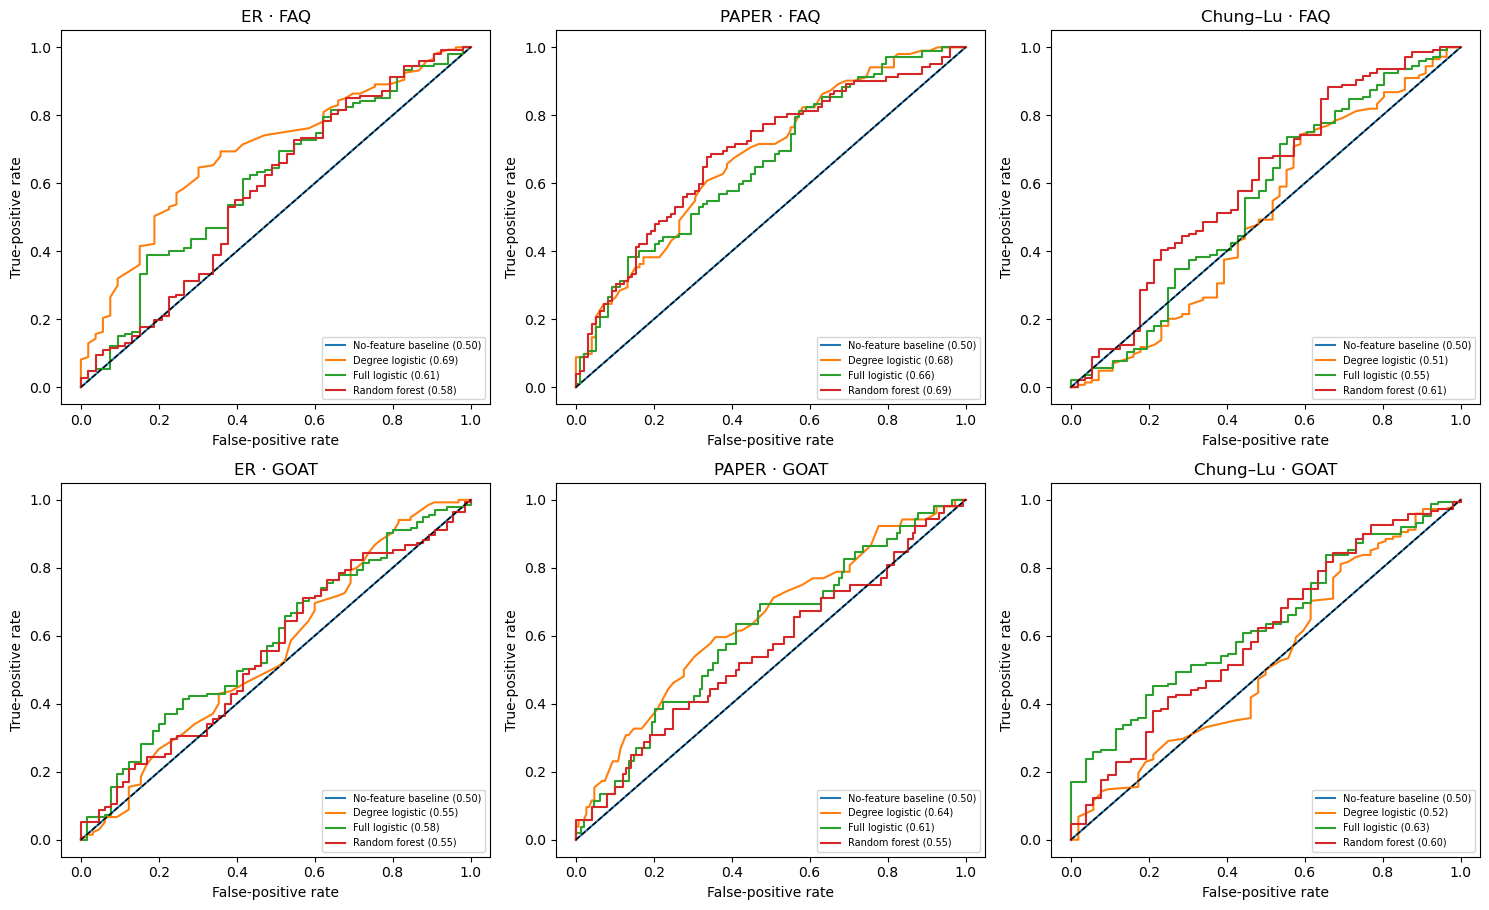

In [9]:
fitted_models = {}
test_probabilities = {}
test_rows = []
paired_rows = []
for key, c in collections.items():
    specs = make_model_specs(c['features'])
    y_test = c['test']['success'].to_numpy()
    scores = {}
    for name, (columns, estimator) in specs.items():
        fitted = clone(estimator).fit(c['fit_train'][columns], c['fit_train']['success'])
        probability = fitted.predict_proba(c['test'][columns])[:, 1]
        prediction = (probability >= 0.5).astype(int)
        fitted_models[(key, name)] = fitted
        test_probabilities[(key, name)] = probability
        scores[name] = probability
        test_rows.append({
            'Dataset': dataset_label(key), 'Model': name,
            'ROC-AUC': roc_auc_score(y_test, probability),
            'Average precision': average_precision_score(y_test, probability),
            'Accuracy': accuracy_score(y_test, prediction),
            'Balanced accuracy': balanced_accuracy_score(y_test, prediction),
            'Brier score': brier_score_loss(y_test, probability),
            'Mean predicted p': probability.mean(),
            'Observed success': y_test.mean(),
        })
    intervals, paired = bootstrap_auc(y_test, scores, reference='Degree logistic')
    for row in test_rows[-len(specs):]:
        row['AUC 95% low'], row['AUC 95% high'] = intervals[row['Model']]
    for name in ('Full logistic', 'Random forest'):
        mean_difference, low, high = paired[name]
        paired_rows.append({'Dataset': dataset_label(key), 'Model': name,
                            'AUC minus degree-only AUC': mean_difference,
                            '95% low': low, '95% high': high})

test_results = pd.DataFrame(test_rows)
auc_table = test_results.pivot(index='Dataset', columns='Model', values='ROC-AUC').reindex(
    index=dataset_order, columns=MODEL_NAMES)
auc_with_ci = auc_table.copy().astype(object)
for row in test_rows:
    auc_with_ci.loc[row['Dataset'], row['Model']] = (
        f"{row['ROC-AUC']:.3f} [{row['AUC 95% low']:.2f}, {row['AUC 95% high']:.2f}]")
print(f'Held-out random-test ROC-AUC, models fitted on TRAIN_ON = {TRAIN_ON!r}')
display(auc_with_ci)
print('Does the full model beat degree alone? Paired bootstrap on the same test sets')
display(pd.DataFrame(paired_rows).set_index(['Dataset', 'Model']).round(3))
print('All held-out metrics')
display(test_results.set_index(['Dataset', 'Model']).drop(columns=['AUC 95% low', 'AUC 95% high']).round(3))

fig, axes = plt.subplots(len(SOLVERS), len(GRAPH_MODELS), figsize=(15, 4.6 * len(SOLVERS)), squeeze=False)
for row, solver in enumerate(SOLVERS):
    for col, model in enumerate(GRAPH_MODELS):
        key = (model, solver)
        ax = axes[row, col]
        y_test = collections[key]['test']['success'].to_numpy()
        for name in MODEL_NAMES:
            fpr, tpr, _ = roc_curve(y_test, test_probabilities[(key, name)])
            ax.plot(fpr, tpr, label=f'{name} ({auc_table.loc[dataset_label(key), name]:.2f})')
        ax.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1)
        ax.set_title(dataset_label(key))
        ax.set_xlabel('False-positive rate')
        ax.set_ylabel('True-positive rate')
        ax.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()

**Do the constructed training sets help?** The same two models are refitted on the 400 random training sets only and on all 800 training sets, then scored on the same test sets.

In [10]:
variant_rows = []
for key, c in collections.items():
    specs = make_model_specs(c['features'])
    y_test = c['test']['success'].to_numpy()
    for name in ('Full logistic', 'Random forest'):
        columns, estimator = specs[name]
        row = {'Dataset': dataset_label(key), 'Model': name}
        for label, rows in [('Random 400', c['random_train']), ('All 800 training', c['train'])]:
            fitted = clone(estimator).fit(rows[columns], rows['success'])
            row[label] = roc_auc_score(y_test, fitted.predict_proba(c['test'][columns])[:, 1])
        variant_rows.append(row)
print('Held-out ROC-AUC by training rows')
display(pd.DataFrame(variant_rows).set_index(['Dataset', 'Model']).round(3))

Held-out ROC-AUC by training rows


Random 400  All 800 training
Dataset         Model                                      
ER · FAQ        Full logistic       0.627             0.607
                Random forest       0.562             0.579
PAPER · FAQ     Full logistic       0.654             0.661
                Random forest       0.641             0.690
Chung–Lu · FAQ  Full logistic       0.562             0.552
                Random forest       0.605             0.605
ER · GOAT       Full logistic       0.581             0.583
                Random forest       0.617             0.552
PAPER · GOAT    Full logistic       0.533             0.607
                Random forest       0.528             0.555
Chung–Lu · GOAT Full logistic       0.599             0.634
                Random forest       0.625             0.601

## 7. Feature importance

**Permutation importance** (primary) measures how much held-out ROC-AUC falls when one predictor is shuffled in the test sets. Correlated predictors can share importance, so a low value does not prove a feature is irrelevant, and importance is predictive rather than causal. With strongly correlated predictors (Section 3), the logistic model can fit large opposing coefficients; shuffling one of them then breaks that balance, so its permutation importance can look large even when the model does not beat degree alone. Read it together with the paired comparison in Section 6.

**Standardized logistic coefficients** show the fitted direction of each linear association (positive means higher values go with success), and random-forest impurity importance shows which features the forest split on during training. Treat both as supporting descriptions.

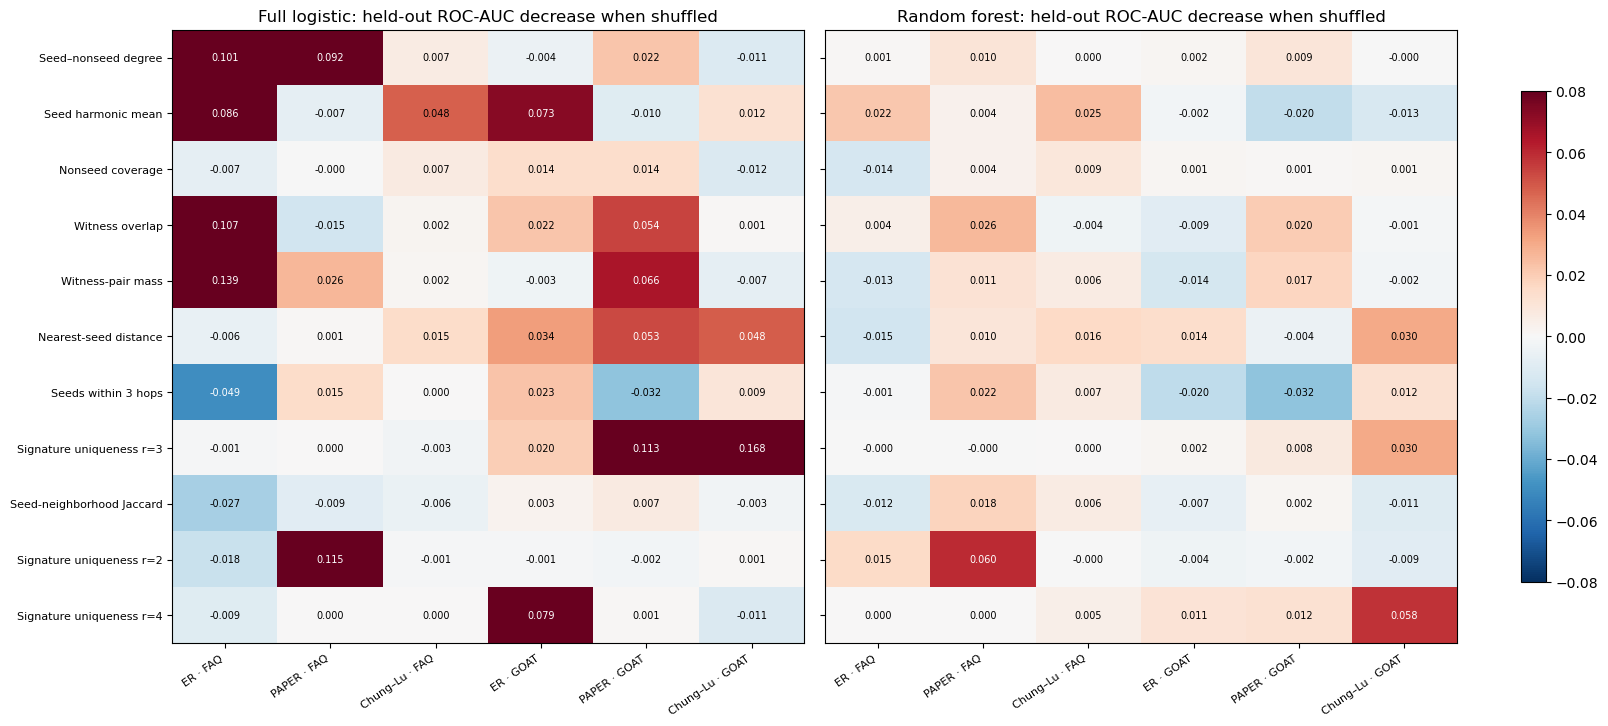

Top three permutation features per dataset


Top features
Dataset         Model                                                           
ER · FAQ        Full logistic  Witness-pair mass (0.139); Witness overlap (0....
                Random forest  Seed harmonic mean (0.022); Signature uniquene...
PAPER · FAQ     Full logistic  Signature uniqueness r=2 (0.115); Seed–nonseed...
                Random forest  Signature uniqueness r=2 (0.060); Witness over...
Chung–Lu · FAQ  Full logistic  Seed harmonic mean (0.048); Nearest-seed dista...
                Random forest  Seed harmonic mean (0.025); Nearest-seed dista...
ER · GOAT       Full logistic  Signature uniqueness r=4 (0.079); Seed harmoni...
                Random forest  Nearest-seed distance (0.014); Signature uniqu...
PAPER · GOAT    Full logistic  Signature uniqueness r=3 (0.113); Witness-pair...
                Random forest  Witness overlap (0.020); Witness-pair mass (0....
Chung–Lu · GOAT Full logistic  Signature uniqueness r=3 (0.168); Nearest-seed...
                Random forest  Signature uniqueness r=4 (0.058); Signature un...

In [11]:
importance_rows = []
for key, c in collections.items():
    specs = make_model_specs(c['features'])
    y_test = c['test']['success'].to_numpy()
    for name in ('Full logistic', 'Random forest'):
        columns = specs[name][0]
        result = permutation_importance(fitted_models[(key, name)], c['test'][columns], y_test,
                                        scoring='roc_auc', n_repeats=PERMUTATION_REPEATS,
                                        random_state=RANDOM_STATE, n_jobs=-1)
        for feature, mean, sd in zip(columns, result.importances_mean, result.importances_std):
            importance_rows.append({'Dataset': dataset_label(key), 'Model': name,
                                    'Feature': feature_label(feature),
                                    'Mean ROC-AUC decrease': mean, 'SD': sd})
permutation_table = pd.DataFrame(importance_rows)
feature_order = [feature_label(f) for f in FEATURE_LABELS
                 if feature_label(f) in set(permutation_table['Feature'])]

fig, axes = plt.subplots(1, 2, figsize=(16, 0.45 * len(feature_order) + 2.2), constrained_layout=True)
for ax, name in zip(axes, ('Full logistic', 'Random forest')):
    table = (permutation_table[permutation_table['Model'].eq(name)]
             .pivot(index='Feature', columns='Dataset', values='Mean ROC-AUC decrease')
             .reindex(index=feature_order, columns=dataset_order))
    image = heatmap(ax, table, vmin=-0.08, vmax=0.08, fmt='{:.3f}')
    ax.set_title(f'{name}: held-out ROC-AUC decrease when shuffled')
axes[1].set_yticklabels([])
fig.colorbar(image, ax=axes, shrink=0.8)
plt.show()

print('Top three permutation features per dataset')
top_rows = []
for (dataset, name), group in permutation_table.groupby(['Dataset', 'Model'], sort=False):
    best = group.sort_values('Mean ROC-AUC decrease', ascending=False).head(3)
    top_rows.append({'Dataset': dataset, 'Model': name, 'Top features': '; '.join(
        f"{row['Feature']} ({row['Mean ROC-AUC decrease']:.3f})" for _, row in best.iterrows())})
display(pd.DataFrame(top_rows).set_index(['Dataset', 'Model']))

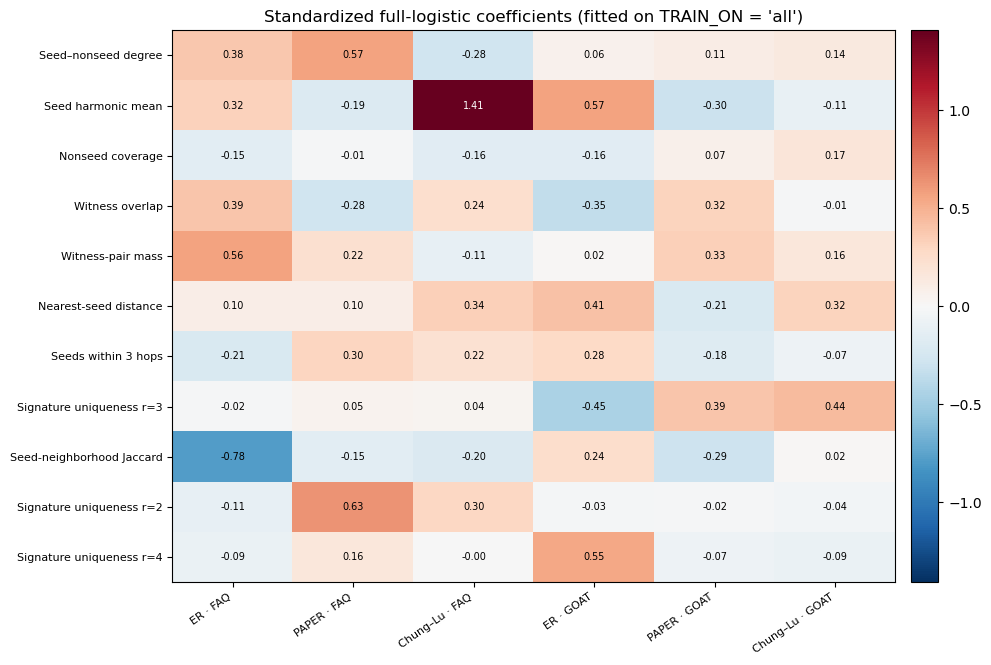

Random-forest impurity importance (training data)


,ER · FAQ,PAPER · FAQ,Chung–Lu · FAQ,ER · GOAT,PAPER · GOAT,Chung–Lu · GOAT
Seed–nonseed degree,0.100,0.113,0.093,0.081,0.093,0.082
Seed harmonic mean,0.132,0.133,0.156,0.133,0.122,0.102
Nonseed coverage,0.086,0.084,0.076,0.066,0.086,0.079
Witness overlap,0.134,0.120,0.113,0.104,0.109,0.102
Witness-pair mass,0.107,0.097,0.110,0.067,0.069,0.063
Nearest-seed distance,0.091,0.087,0.079,0.081,0.081,0.092
Seeds within 3 hops,0.126,0.122,0.129,0.116,0.092,0.101
Signature uniqueness r=3,0.001,0.001,0.025,0.091,0.095,0.110
Seed-neighborhood Jaccard,0.127,0.110,0.116,0.114,0.094,0.112
Signature uniqueness r=2,0.095,0.132,0.091,0.059,0.066,0.055


In [12]:
coefficients = {}
forest_importance = {}
for key, c in collections.items():
    logistic = fitted_models[(key, 'Full logistic')].named_steps['model']
    forest = fitted_models[(key, 'Random forest')].named_steps['model']
    coefficients[dataset_label(key)] = dict(zip([feature_label(f) for f in c['features']], logistic.coef_[0]))
    forest_importance[dataset_label(key)] = dict(zip([feature_label(f) for f in c['features']],
                                                     forest.feature_importances_))
coefficients = pd.DataFrame(coefficients).reindex(index=feature_order, columns=dataset_order)
forest_importance = pd.DataFrame(forest_importance).reindex(index=feature_order, columns=dataset_order)

limit = float(np.nanmax(np.abs(coefficients.to_numpy()))) if coefficients.notna().any().any() else 1.0
fig, ax = plt.subplots(figsize=(10, 0.45 * len(feature_order) + 1.8))
image = heatmap(ax, coefficients, vmin=-limit, vmax=limit)
ax.set_title(f'Standardized full-logistic coefficients (fitted on TRAIN_ON = {TRAIN_ON!r})')
fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02)
plt.tight_layout()
plt.show()
print('Random-forest impurity importance (training data)')
display(forest_importance.round(3))

## 8. Reference diagnostic: edge noise around the seeds

This section uses **graph B and the true matching**, so it is not something a seed-selection rule could compute. It asks how much of the outcome depends on which of the seeds' edges survived in graph B, which Graph A cannot reveal.

For each seed set it counts:
- the seed–nonseed edges in A;
- how many of those edges were kept in B under the true matching;
- the kept share.

The comparison model adds the kept share to the Graph-A predictors. Its held-out AUC is a rough reference for how much a Graph-A-only model leaves on the table. `h0_accuracy` (first-step accuracy) is shown for reference too.

In [13]:
if RUN_NOISE_DIAGNOSTIC:
    noise_rows = []
    for key, c in collections.items():
        model, solver = key
        metadata = c['metadata']
        if 'graph_pair_dir_relative' in metadata:
            pair_dir = (c['folder'] / metadata['graph_pair_dir_relative']).resolve()
        else:
            pair_dir = Path(metadata['graph_pair_dir'])
        with np.load(pair_dir / f'{model}_problem.npz') as saved:
            A = saved['adjacency_graph1'].astype(np.int32)
            B = saved['adjacency_graph2'].astype(np.int32)
            truth = saved['true_permutation'].astype(int)
        kept_edges = A * B[np.ix_(truth, truth)]  # edges present in both graphs under the true matching

        data = c['data']
        seed_edges_a, seed_edges_kept = [], []
        nonseed = np.ones(len(A), dtype=bool)
        for value in data['seed_vertices_graph1']:
            seeds = np.asarray(json.loads(value), dtype=int)
            nonseed[:] = True
            nonseed[seeds] = False
            seed_edges_a.append(A[np.ix_(seeds, nonseed)].sum())
            seed_edges_kept.append(kept_edges[np.ix_(seeds, nonseed)].sum())
        data['seed_edges_in_A'] = np.asarray(seed_edges_a, dtype=float)
        data['seed_edges_kept_in_B'] = np.asarray(seed_edges_kept, dtype=float)
        data['kept_share'] = data['seed_edges_kept_in_B'] / data['seed_edges_in_A']
        for part in ('train', 'random_train', 'test', 'fit_train'):
            c[part] = data.loc[c[part].index]

        test = c['test']
        y_test = test['success'].to_numpy()
        reference = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', LogisticRegression(C=1.0, max_iter=5000, random_state=RANDOM_STATE)),
        ]).fit(c['fit_train'][c['features'] + ['kept_share']], c['fit_train']['success'])
        noise_rows.append({
            'Dataset': dataset_label(key),
            'Retained edge fraction (pair)': kept_edges.sum() / A.sum(),
            'AUC: seed edges in A': roc_auc_score(y_test, test['seed_edges_in_A']),
            'AUC: seed edges kept in B': roc_auc_score(y_test, test['seed_edges_kept_in_B']),
            'AUC: kept share': roc_auc_score(y_test, test['kept_share']),
            'AUC: h0_accuracy': roc_auc_score(y_test, test['h0_accuracy']),
            'AUC: Graph-A full logistic': auc_table.loc[dataset_label(key), 'Full logistic'],
            'AUC: Graph-A + kept share': roc_auc_score(
                y_test, reference.predict_proba(test[c['features'] + ['kept_share']])[:, 1]),
        })
    print('Held-out ROC-AUC on the random test sets (reference only: uses graph B and the truth)')
    display(pd.DataFrame(noise_rows).set_index('Dataset').round(3))
else:
    print('Skipped: set RUN_NOISE_DIAGNOSTIC = True to run this section.')

Held-out ROC-AUC on the random test sets (reference only: uses graph B and the truth)


,Retained edge fraction (pair),AUC: seed edges in A,AUC: seed edges kept in B,AUC: kept share,AUC: h0_accuracy,AUC: Graph-A full logistic,AUC: Graph-A + kept share
Dataset,,,,,,,
ER · FAQ,0.529,0.691,0.780,0.718,0.909,0.607,0.733
PAPER · FAQ,0.479,0.679,0.730,0.668,0.838,0.661,0.705
Chung–Lu · FAQ,0.483,0.506,0.547,0.608,0.814,0.552,0.635
ER · GOAT,0.529,0.551,0.690,0.714,0.714,0.583,0.752
PAPER · GOAT,0.479,0.641,0.735,0.726,0.826,0.607,0.730
Chung–Lu · GOAT,0.483,0.476,0.526,0.621,0.695,0.634,0.671


## 9. Summary

For each dataset, the summary lists:
- the success rate on random sets;
- the best held-out model;
- whether the full models beat degree alone;
- the top random-forest features.

The **selection check** ranks the 200 test sets by the random forest's predicted probability. It compares the success rate of the top 10% and 25% with the overall rate. That is the practical question for seed selection: does picking the top-ranked sets beat picking at random? With 20 and 50 sets these rates are noisy.

In [14]:
summary_rows = []
for key, c in collections.items():
    label = dataset_label(key)
    results = test_results[test_results['Dataset'].eq(label)].set_index('Model')
    nonbaseline = results.drop(index='No-feature baseline')
    best = nonbaseline['ROC-AUC'].idxmax()
    forest_difference = next(r for r in paired_rows if r['Dataset'] == label and r['Model'] == 'Random forest')
    top = (permutation_table[(permutation_table['Dataset'] == label) & (permutation_table['Model'] == 'Random forest')]
           .sort_values('Mean ROC-AUC decrease', ascending=False).head(3)['Feature'])
    ranked = c['test'].assign(p=test_probabilities[(key, 'Random forest')]).sort_values('p', ascending=False)
    summary_rows.append({
        'Dataset': label,
        'k': c['metadata']['config']['n_seeds'],
        'Random-set success': c['data'].loc[c['data']['sampling_strategy'].eq('random'), 'success'].mean(),
        'Best model': best,
        'Best held-out AUC': f"{results.loc[best, 'ROC-AUC']:.3f} [{results.loc[best, 'AUC 95% low']:.2f}, "
                             f"{results.loc[best, 'AUC 95% high']:.2f}]",
        'Forest minus degree AUC': f"{forest_difference['AUC minus degree-only AUC']:+.3f} "
                                   f"[{forest_difference['95% low']:+.2f}, {forest_difference['95% high']:+.2f}]",
        'Top forest features': '; '.join(top),
        'Test success: all 200': ranked['success'].mean(),
        'Top 25% by forest': ranked['success'].head(int(round(0.25 * len(ranked)))).mean(),
        'Top 10% by forest': ranked['success'].head(int(round(0.10 * len(ranked)))).mean(),
    })
display(pd.DataFrame(summary_rows).set_index('Dataset').round(3))

,k,Random-set success,Best model,Best held-out AUC,Forest minus degree AUC,Top forest features,Test success: all 200,Top 25% by forest,Top 10% by forest
Dataset,,,,,,,,,
ER · FAQ,29,0.737,Degree logistic,"0.691 [0.61, 0.77]","-0.112 [-0.21, -0.02]",Seed harmonic mean; Signature uniqueness r=2; ...,0.735,0.76,0.80
PAPER · FAQ,31,0.530,Random forest,"0.690 [0.61, 0.76]","+0.010 [-0.05, +0.07]",Signature uniqueness r=2; Witness overlap; See...,0.510,0.70,0.80
Chung–Lu · FAQ,27,0.692,Random forest,"0.605 [0.51, 0.69]","+0.097 [+0.01, +0.18]",Seed harmonic mean; Nearest-seed distance; Non...,0.720,0.80,0.80
ER · GOAT,12,0.668,Full logistic,"0.583 [0.49, 0.67]","+0.004 [-0.10, +0.10]",Nearest-seed distance; Signature uniqueness r=...,0.675,0.70,0.70
PAPER · GOAT,12,0.270,Degree logistic,"0.641 [0.55, 0.73]","-0.085 [-0.16, -0.02]",Witness overlap; Witness-pair mass; Signature ...,0.260,0.32,0.35
Chung–Lu · GOAT,9,0.672,Full logistic,"0.634 [0.55, 0.72]","+0.074 [-0.03, +0.19]",Signature uniqueness r=4; Signature uniqueness...,0.740,0.80,0.85


## Interpretation limits

- Each model is one fixed graph pair. Repeat on the other calibration pairs before claiming that a ranking or a feature effect transfers to new graph draws.
- FAQ and GOAT use different seed budgets, so their AUCs answer *how predictable is this solver at its own balanced budget*, not which solver is better.
- A FAQ label is one run and can flip with the solver's RNG near the transition, which lowers the AUC any Graph-A model can reach for FAQ. GOAT labels are reproducible.
- 200 test sets give AUC intervals of roughly ±0.08; differences smaller than that are not reliable.
- Constructed training sets widen the feature range but are not a random sample; the held-out test sets are uniformly random, which is the reference population for all test metrics.
- Feature importance and coefficients are predictive, not causal. The degree-matched contrasts in Section 4 are the closest check of effects beyond degree.
- Section 8 uses graph B and the truth and is a reference diagnostic only.